In [ ]:
!pip install tensorflow matplotlib numpy pandas scikit-learn pillow fastapi uvicorn python-multipart

In [7]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [13]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [4]:

import os

print(os.listdir("/content/drive/MyDrive"))


['Colab Notebooks', 'NPAAT-2.docx', 'DISH Network _(Registrations-UG) - 2027-3.xlsx', 'Deloitte_29th_Sep_Registrations_UG_South_Asia_Applicant_Database_Propel_Junior_Associate-1.xlsx', 'Final 7th Sem PE STUDENTS LIST as on 27-07-2026 with new Classrooms (1).xlsx', 'Tejas_Networks_(Registrations-UG,PG) - 2027.xlsx', 'Natwest_ 2027-1.xlsx', 'Natwest Format 2027 (Registrations - UG)-9.xlsx', 'Thoughtworks_Format_(Registrations-UG) - 2027.xlsx', 'PlantVillage', 'DL_Project.zip']


In [11]:

import os

print(os.listdir("/content/drive/MyDrive"))


['NPAAT-2.docx', 'DISH Network _(Registrations-UG) - 2027-3.xlsx', 'Deloitte_29th_Sep_Registrations_UG_South_Asia_Applicant_Database_Propel_Junior_Associate-1.xlsx', 'Final 7th Sem PE STUDENTS LIST as on 27-07-2026 with new Classrooms (1).xlsx', 'Tejas_Networks_(Registrations-UG,PG) - 2027.xlsx', 'Natwest_ 2027-1.xlsx', 'Natwest Format 2027 (Registrations - UG)-9.xlsx', 'Colab Notebooks', 'Thoughtworks_Format_(Registrations-UG) - 2027.xlsx', 'PlantVillage', 'PlantVillage.zip']


In [14]:
import zipfile
import os

ZIP_PATH = "/content/drive/MyDrive/PlantVillage.zip"
EXTRACT_PATH = "/content/PlantVillage"

if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError(f"ZIP file not found: {ZIP_PATH}")

os.makedirs(EXTRACT_PATH, exist_ok=True)

print("Extracting dataset, this might take a moment...")
with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("ZIP file extracted successfully!")

Extracting dataset, this might take a moment...
ZIP file extracted successfully!


In [15]:

print(os.listdir(EXTRACT_PATH)[:20])


['PlantVillage', '__MACOSX']


In [16]:

import os

DATA_DIR = "/content/PlantVillage/PlantVillage"

print("Dataset path exists:", os.path.exists(DATA_DIR))
print("Folders inside the dataset:")

for folder in os.listdir(DATA_DIR):
    print(folder)


Dataset path exists: True
Folders inside the dataset:
Potato___Early_blight
Potato___Late_blight
.DS_Store
Potato___healthy


In [17]:
import pathlib

DATA_DIR_PATH = pathlib.Path(DATA_DIR)
# Get all subdirectories within DATA_DIR, ignoring hidden files/folders
class_folders = [p for p in DATA_DIR_PATH.iterdir() if p.is_dir() and not p.name.startswith('.')]

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

image_paths = []
labels = []

for folder in class_folders:
    files = [
        path for path in folder.iterdir()
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    print(folder.name, ":", len(files), "images")

    for path in files:
        image_paths.append(path)
        labels.append(folder.name)

print("\nTotal images:", len(image_paths))

Potato___Early_blight : 1000 images
Potato___Late_blight : 1000 images
Potato___healthy : 152 images

Total images: 2152


In [18]:
from PIL import Image

bad_files = []

for path in image_paths:
    try:
        with Image.open(path) as img:
            img.verify()
    except Exception as exc:
        bad_files.append((str(path), str(exc)))

print("Total images checked:", len(image_paths))
print("Unreadable images:", len(bad_files))

for path, error in bad_files[:10]:
    print(path, "->", error)

Total images checked: 2152
Unreadable images: 0


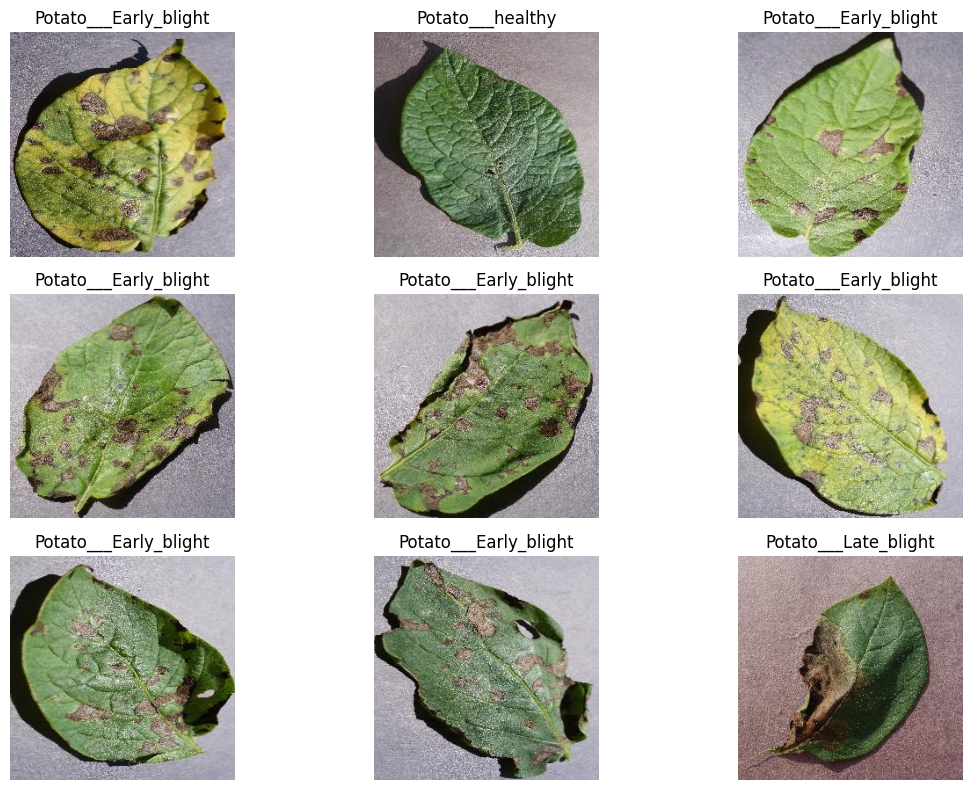

In [14]:
from PIL import Image
import matplotlib.pyplot as plt
import random

random.seed(42)

if not image_paths:
    raise ValueError("No images found. Check the dataset path.")

sample_indices = random.sample(
    range(len(image_paths)),
    min(9, len(image_paths))
)

plt.figure(figsize=(12, 8))

for i, index in enumerate(sample_indices):
    path = image_paths[index]

    with Image.open(path) as img:
        image = img.convert("RGB")

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(path.parent.name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [21]:

from pathlib import Path

DATA_DIR = Path("/content/PlantVillage/PlantVillage")

CLASS_NAMES = [
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy"
]

for class_name in CLASS_NAMES:
    folder = DATA_DIR / class_name
    if not folder.is_dir():
        raise FileNotFoundError(
            f"Missing class folder: {folder}"
        )

print("All three potato classes were found.")


All three potato classes were found.


In [20]:
from sklearn.model_selection import train_test_split
from PIL import Image
from pathlib import Path

DATA_DIR = Path("/content/PlantVillage/PlantVillage")
CLASS_NAMES = [
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy"
]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

valid_paths = []
valid_labels = []

# Safely collect all valid image paths and labels
for class_name in CLASS_NAMES:
    folder = DATA_DIR / class_name
    if folder.is_dir():
        for path in folder.iterdir():
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
                valid_paths.append(str(path))
                valid_labels.append(class_name)

if len(set(valid_labels)) != 3:
    raise ValueError("All three classes must contain images. Please ensure the dataset is fully extracted.")

# First: 70% train, 30% temporary (validation + test)
X_train, X_temp, y_train, y_temp = train_test_split(
    valid_paths,
    valid_labels,
    test_size=0.30,
    random_state=42,
    stratify=valid_labels
)

# Then: split temporary data equally into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))
print("Total:", len(X_train) + len(X_val) + len(X_test))

Training images: 1506
Validation images: 323
Testing images: 323
Total: 2152


In [22]:
import tensorflow as tf
import numpy as np

CLASS_NAMES = [
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy"
]

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

class_to_index = {
    name: index for index, name in enumerate(CLASS_NAMES)
}

y_train_num = np.array([class_to_index[y] for y in y_train])
y_val_num = np.array([class_to_index[y] for y in y_val])
y_test_num = np.array([class_to_index[y] for y in y_test])

def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(
            buffer_size=min(len(paths), 1000),
            seed=42
        )
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(X_train, y_train_num, training=True)
val_ds = make_dataset(X_val, y_val_num)
test_ds = make_dataset(X_test, y_test_num)

print("Image preprocessing completed.")

Image preprocessing completed.


In [23]:

from tensorflow.keras import layers, models

data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="data_augmentation")

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Applied only during training
    data_augmentation,

    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(256, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    # Three output probabilities
    layers.Dense(3, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,699 (1.61 MB)

 Trainable params: 421,699 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        "/content/best_potato_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)


Epoch 1/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 12s 86ms/step - accuracy: 0.5153 - loss: 0.8848 - val_accuracy: 0.5449 - val_loss: 0.8798
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - accuracy: 0.5677 - loss: 0.8499 - val_accuracy: 0.6223 - val_loss: 0.8328
Epoch 3/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step - accuracy: 0.7244 - loss: 0.7009 - val_accuracy: 0.7399 - val_loss: 0.6674
Epoch 4/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - accuracy: 0.8041 - loss: 0.5326 - val_accuracy: 0.6811 - val_loss: 0.8712
Epoch 5/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - accuracy: 0.8353 - loss: 0.4432 - val_accuracy: 0.5759 - val_loss: 1.4708
Epoch 6/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - accuracy: 0.8260 - loss: 0.4713 - val_accuracy: 0.7771 - val_loss: 0.7089


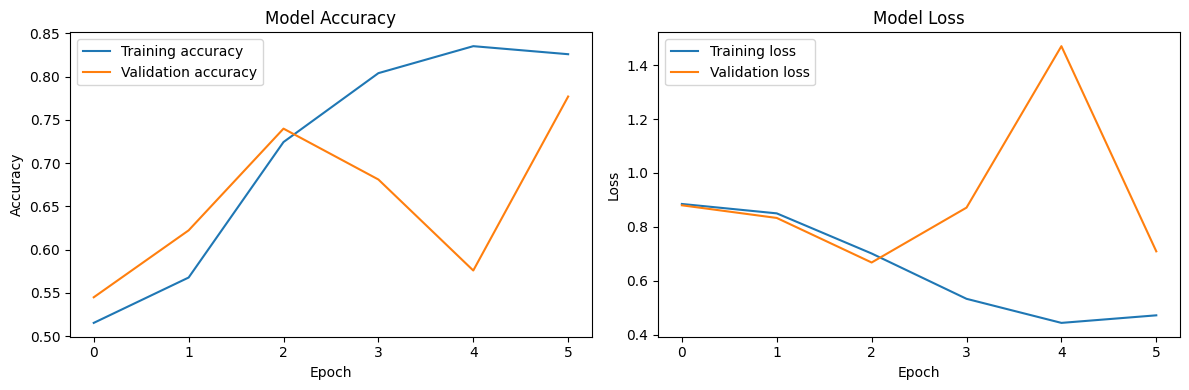

In [25]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [26]:

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7028 - loss: 0.6453
Test loss: 0.6453
Test accuracy: 70.28%


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step
                       precision    recall  f1-score   support

Potato___Early_blight       0.66      0.97      0.79       150
 Potato___Late_blight       0.79      0.54      0.64       150
     Potato___healthy       0.00      0.00      0.00        23

             accuracy                           0.70       323
            macro avg       0.48      0.50      0.48       323
         weighted avg       0.67      0.70      0.66       323



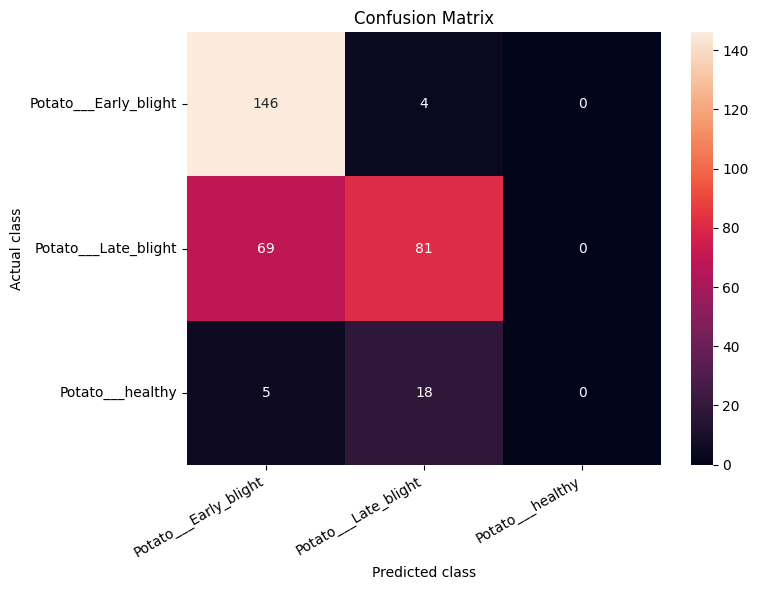

In [27]:

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

probabilities = model.predict(test_ds)
y_pred = np.argmax(probabilities, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Confusion Matrix")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [28]:

import matplotlib.pyplot as plt

print("Final training accuracy:",
      f"{history.history['accuracy'][-1] * 100:.2f}%")

print("Final validation accuracy:",
      f"{history.history['val_accuracy'][-1] * 100:.2f}%")

print("Final training loss:",
      f"{history.history['loss'][-1]:.4f}")

print("Final validation loss:",
      f"{history.history['val_loss'][-1]:.4f}")


Final training accuracy: 82.60%
Final validation accuracy: 77.71%
Final training loss: 0.4713
Final validation loss: 0.7089


In [29]:

import tensorflow as tf
from tensorflow.keras import layers, models

IMG_SIZE = (224, 224)

# Load MobileNetV2 pretrained on ImageNet
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Initially freeze pretrained layers
base_model.trainable = False

print("MobileNetV2 loaded successfully.")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully.


In [30]:

data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10)
], name="data_augmentation")

inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

# Your existing dataset is normalized to [0, 1].
# MobileNetV2 expects inputs scaled to [-1, 1].
x = layers.Rescaling(scale=2.0, offset=-1.0)(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(3, activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [31]:

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        "/content/best_potato_mobilenet.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)


Epoch 1/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 16s 134ms/step - accuracy: 0.7902 - loss: 0.5882 - val_accuracy: 0.9257 - val_loss: 0.2322 - learning_rate: 0.0010
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step - accuracy: 0.9256 - loss: 0.2174 - val_accuracy: 0.9628 - val_loss: 0.1443 - learning_rate: 0.0010
Epoch 3/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 85ms/step - accuracy: 0.9429 - loss: 0.1664 - val_accuracy: 0.9659 - val_loss: 0.1294 - learning_rate: 0.0010
Epoch 4/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step - accuracy: 0.9482 - loss: 0.1396 - val_accuracy: 0.9690 - val_loss: 0.1098 - learning_rate: 0.0010
Epoch 5/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step - accuracy: 0.9628 - loss: 0.1155 - val_accuracy: 0.9721 - val_loss: 0.1024 - learning_rate: 0.0010
Epoch 6/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step - accuracy: 0.9661 - loss: 0.1004 - val_accuracy: 0.9690 - val_loss: 0.0888 - learning_rate: 0.0010
Epoch 7/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 88ms/step - accuracy: 0.9708 - loss: 0.0942 - val_a

In [32]:

base_model.trainable = True

# Freeze most layers; fine-tune only the final 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stability
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)


Epoch 1/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 15s 114ms/step - accuracy: 0.9841 - loss: 0.0441 - val_accuracy: 0.9628 - val_loss: 0.1057 - learning_rate: 1.0000e-05
Epoch 2/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 6s 96ms/step - accuracy: 0.9841 - loss: 0.0447 - val_accuracy: 0.9628 - val_loss: 0.0643 - learning_rate: 1.0000e-05
Epoch 3/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 94ms/step - accuracy: 0.9907 - loss: 0.0301 - val_accuracy: 0.9752 - val_loss: 0.0440 - learning_rate: 1.0000e-05
Epoch 4/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 82ms/step - accuracy: 0.9841 - loss: 0.0396 - val_accuracy: 0.9783 - val_loss: 0.0446 - learning_rate: 1.0000e-05
Epoch 5/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 6s 97ms/step - accuracy: 0.9914 - loss: 0.0229 - val_accuracy: 0.9938 - val_loss: 0.0279 - learning_rate: 1.0000e-05
Epoch 6/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 84ms/step - accuracy: 0.9894 - loss: 0.0254 - val_accuracy: 0.9814 - val_loss: 0.0318 - learning_rate: 1.0000e-05
Epoch 7/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 6s 98ms/step - accuracy: 0.997

In [33]:

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Final test accuracy: {test_accuracy * 100:.2f}%")
print(f"Final test loss: {test_loss:.4f}")


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.9938 - loss: 0.0161
Final test accuracy: 99.38%
Final test loss: 0.0161


11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 178ms/step
                       precision    recall  f1-score   support

Potato___Early_blight     1.0000    0.9933    0.9967       150
 Potato___Late_blight     0.9868    1.0000    0.9934       150
     Potato___healthy     1.0000    0.9565    0.9778        23

             accuracy                         0.9938       323
            macro avg     0.9956    0.9833    0.9893       323
         weighted avg     0.9939    0.9938    0.9938       323



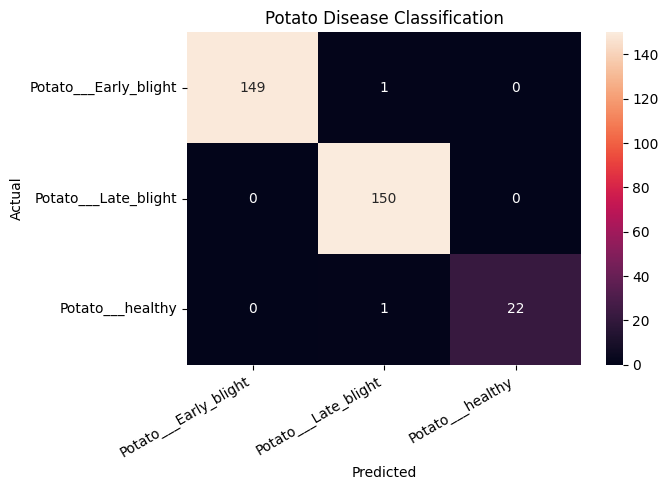

In [34]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    digits=4
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Potato Disease Classification")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [35]:
model.save("/content/potato_disease_model.keras")

import json

with open("/content/class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f, indent=2)

print("Model and class names saved successfully.")

Model and class names saved successfully.


In [36]:

# Evaluate the trained MobileNetV2 model on test data

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"\nTest Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.9938 - loss: 0.0161

Test Accuracy: 99.38%
Test Loss: 0.0161


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step
                       precision    recall  f1-score   support

Potato___Early_blight     1.0000    0.9933    0.9967       150
 Potato___Late_blight     0.9868    1.0000    0.9934       150
     Potato___healthy     1.0000    0.9565    0.9778        23

             accuracy                         0.9938       323
            macro avg     0.9956    0.9833    0.9893       323
         weighted avg     0.9939    0.9938    0.9938       323



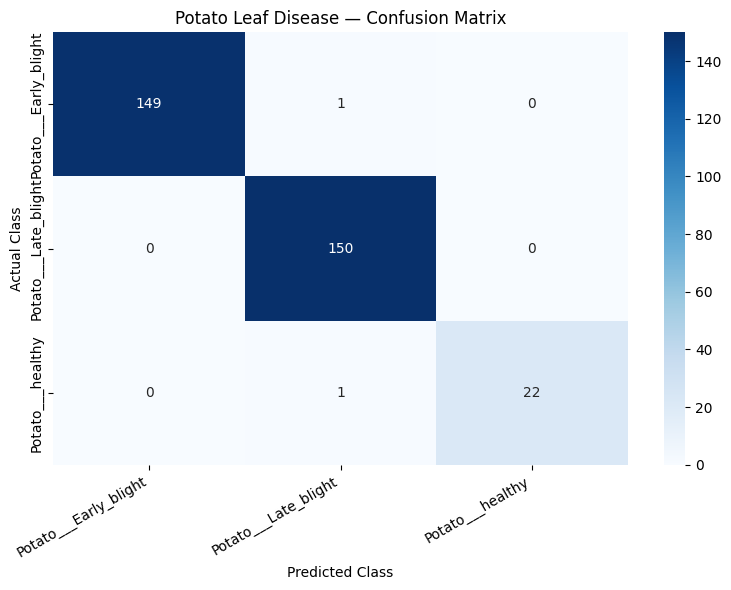

In [37]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Actual labels
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

# Predicted labels
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

# Precision, recall, F1-score
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Potato Leaf Disease — Confusion Matrix")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [38]:

train_acc = fine_tune_history.history["accuracy"][-1] * 100
val_acc = fine_tune_history.history["val_accuracy"][-1] * 100

_, test_acc = model.evaluate(test_ds, verbose=0)
test_acc *= 100

print(f"Training Accuracy:   {train_acc:.2f}%")
print(f"Validation Accuracy: {val_acc:.2f}%")
print(f"Test Accuracy:       {test_acc:.2f}%")


Training Accuracy:   99.34%
Validation Accuracy: 98.76%
Test Accuracy:       99.38%


In [39]:

import json
from pathlib import Path

MODEL_PATH = "/content/potato_disease_model.keras"
CLASS_PATH = "/content/class_names.json"

# Save the trained model
model.save(MODEL_PATH)

# Save the class names in prediction order
with open(CLASS_PATH, "w") as f:
    json.dump(CLASS_NAMES, f, indent=2)

print("Model saved:", Path(MODEL_PATH).exists())
print("Class names saved:", Path(CLASS_PATH).exists())
print("Classes:", CLASS_NAMES)


Model saved: True
Class names saved: True
Classes: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


In [40]:

from google.colab import files

files.download("/content/potato_disease_model.keras")
files.download("/content/class_names.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:

!pip install -q fastapi uvicorn python-multipart


In [42]:

import os

MODEL_PATH = "/content/potato_disease_model.keras"
CLASS_PATH = "/content/class_names.json"

print("Model exists:", os.path.exists(MODEL_PATH))
print("Class names exist:", os.path.exists(CLASS_PATH))


Model exists: True
Class names exist: True


In [43]:

%%writefile /content/app.py

import io
import json
import numpy as np
import tensorflow as tf

from PIL import Image, UnidentifiedImageError
from fastapi import FastAPI, File, UploadFile
from fastapi.responses import HTMLResponse

MODEL_PATH = "/content/potato_disease_model.keras"
CLASS_PATH = "/content/class_names.json"

app = FastAPI(title="Potato Leaf Disease Classifier")

# Load the trained model and class names
model = tf.keras.models.load_model(MODEL_PATH)

with open(CLASS_PATH, "r") as f:
    CLASS_NAMES = json.load(f)


HTML_PAGE = """
<!DOCTYPE html>
<html>
<head>
    <title>Potato Leaf Disease Classifier</title>
    <meta name="viewport" content="width=device-width, initial-scale=1">
    <style>
        body {
            font-family: Arial, sans-serif;
            background: #f1f8f2;
            text-align: center;
            padding: 35px 15px;
        }
        .card {
            background: white;
            max-width: 560px;
            margin: auto;
            padding: 28px;
            border-radius: 16px;
            box-shadow: 0 4px 18px #00000015;
        }
        h1 { color: #216e39; }
        input { margin: 20px 0; max-width: 100%; }
        button {
            background: #278344;
            color: white;
            border: none;
            border-radius: 8px;
            padding: 12px 22px;
            cursor: pointer;
        }
        .result {
            margin-top: 24px;
            padding: 16px;
            background: #edf7ed;
            border-radius: 10px;
        }
        img { max-width: 100%; max-height: 280px; }
    </style>
</head>
<body>
    <div class="card">
        <h1>Potato Leaf Disease Detection</h1>
        <p>Upload a potato leaf image to predict its class.</p>

        <form action="/predict" method="post" enctype="multipart/form-data">
            <input type="file" name="file" accept="image/*" required>
            <br>
            <button type="submit">Predict Disease</button>
        </form>

        {result}
    </div>
</body>
</html>
"""


@app.get("/", response_class=HTMLResponse)
async def home():
    return HTML_PAGE.format(result="")


@app.post("/predict", response_class=HTMLResponse)
async def predict(file: UploadFile = File(...)):
    if not file.content_type or not file.content_type.startswith("image/"):
        return HTML_PAGE.format(
            result="<div class='result'>Please upload an image file.</div>"
        )

    try:
        contents = await file.read()

        # Decode and resize the uploaded image
        with Image.open(io.BytesIO(contents)) as img:
            image = img.convert("RGB").resize((224, 224))

        # Match the training pipeline: scale to [0, 1].
        # The saved model's Rescaling layer then maps to [-1, 1].
        array = np.asarray(image, dtype=np.float32) / 255.0
        array = np.expand_dims(array, axis=0)

        # Predict the class
        probabilities = model.predict(array, verbose=0)[0]
        predicted_index = int(np.argmax(probabilities))
        predicted_class = CLASS_NAMES[predicted_index]
        confidence = float(probabilities[predicted_index]) * 100

        readable_name = predicted_class.replace("Potato___", "").replace("_", " ")

        result_html = f"""
        <div class="result">
            <h2>Prediction: {readable_name}</h2>
            <p>Model confidence: {confidence:.2f}%</p>
            <p>File: {file.filename}</p>
        </div>
        """

        return HTML_PAGE.format(result=result_html)

    except (UnidentifiedImageError, OSError, ValueError):
        return HTML_PAGE.format(
            result="<div class='result'>Unable to read this image. Try another image.</div>"
        )


Writing /content/app.py


In [44]:

import subprocess
import time
import requests

server = subprocess.Popen(
    [
        "uvicorn",
        "app:app",
        "--host", "0.0.0.0",
        "--port", "8000"
    ],
    cwd="/content",
    stdout=open("/content/uvicorn.log", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(5)

if server.poll() is not None:
    print(open("/content/uvicorn.log").read())
else:
    print("FastAPI server is running on port 8000.")


FastAPI server is running on port 8000.


In [54]:

from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8000)")
print("Open your Potato Disease Detection app:")
print(url)


Open your Potato Disease Detection app:
https://8000-gpu-t4-s-usw4a1-2u1qcu0vhpv3r-a.us-west4.prod.r.colab.dev


In [46]:

import requests

response = requests.get("http://127.0.0.1:8000/")
print("HTTP status:", response.status_code)
print("Web app is responding:", response.status_code == 200)


HTTP status: 500
Web app is responding: False


In [47]:

with open("/content/uvicorn.log", "r") as f:
    print(f.read()[-10000:])


W0000 00:00:1793206149.755610    6016 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [6016]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
INFO:     127.0.0.1:38900 - "GET / HTTP/1.1" 500 Internal Server Error
ERROR:    Exception in ASGI application
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/uvicorn/protocols/http/httptools_impl.py", line 422, in run_asgi
    result = await app(  # type: ignore[func-returns-value]
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        self.scope, self.receive, self.send
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/uvicorn/middleware/proxy_headers.py", line 63, in __call__
    return await self.app(

In [48]:

import os

for path in [
    "/content/app.py",
    "/content/potato_disease_model.keras",
    "/content/class_names.json"
]:
    print(path, "->", os.path.exists(path))


/content/app.py -> True
/content/potato_disease_model.keras -> True
/content/class_names.json -> True


In [49]:

import tensorflow as tf
import json

MODEL_PATH = "/content/potato_disease_model.keras"
CLASS_PATH = "/content/class_names.json"

try:
    test_model = tf.keras.models.load_model(MODEL_PATH)
    print("Model loaded successfully.")
    print("Input shape:", test_model.input_shape)
    print("Output shape:", test_model.output_shape)

    with open(CLASS_PATH, "r") as f:
        test_classes = json.load(f)

    print("Classes:", test_classes)

except Exception as e:
    print("Model loading failed:")
    print(type(e).__name__, str(e))


Model loaded successfully.
Input shape: (None, 224, 224, 3)
Output shape: (None, 3)
Classes: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


In [50]:

app_path = "/content/app.py"

with open(app_path, "r") as f:
    code = f.read()

code = code.replace(
    'return HTML_PAGE.format(result="")',
    'return HTML_PAGE.replace("{result}", "")'
)

code = code.replace(
    'return HTML_PAGE.format(result=result_html)',
    'return HTML_PAGE.replace("{result}", result_html)'
)

code = code.replace(
    'return HTML_PAGE.format(\n            result="<div class=\'result\'>Please upload an image file.</div>"\n        )',
    'return HTML_PAGE.replace("{result}", "<div class=\'result\'>Please upload an image file.</div>")'
)

code = code.replace(
    'return HTML_PAGE.format(\n            result="<div class=\'result\'>Unable to read this image. Try another image.</div>"\n        )',
    'return HTML_PAGE.replace("{result}", "<div class=\'result\'>Unable to read this image. Try another image.</div>")'
)

with open(app_path, "w") as f:
    f.write(code)

print("Updated HTML response formatting.")


Updated HTML response formatting.


In [51]:

with open("/content/app.py", "r") as f:
    for line_number, line in enumerate(f, start=1):
        if "HTML_PAGE.format" in line:
            print("Still needs fixing at line:", line_number)

print("Verification complete.")


Verification complete.


In [52]:

server.terminate()
server.wait()

import subprocess
import time

server = subprocess.Popen(
    [
        "uvicorn",
        "app:app",
        "--host", "0.0.0.0",
        "--port", "8000"
    ],
    cwd="/content",
    stdout=open("/content/uvicorn.log", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Server running:", server.poll() is None)


Server running: True


In [53]:

import requests

response = requests.get("http://127.0.0.1:8000/")

print("HTTP status:", response.status_code)
print("Homepage loaded:", response.status_code == 200)
print(response.text[:200])


HTTP status: 200
Homepage loaded: True

<!DOCTYPE html>
<html>
<head>
    <title>Potato Leaf Disease Classifier</title>
    <meta name="viewport" content="width=device-width, initial-scale=1">
    <style>
        body {
            font-fa


In [55]:

import requests

response = requests.get("http://127.0.0.1:8000/")

print("Status:", response.status_code)
print("Response length:", len(response.text))
print("HTML preview:")
print(response.text[:1000])


Status: 200
Response length: 1480
HTML preview:

<!DOCTYPE html>
<html>
<head>
    <title>Potato Leaf Disease Classifier</title>
    <meta name="viewport" content="width=device-width, initial-scale=1">
    <style>
        body {
            font-family: Arial, sans-serif;
            background: #f1f8f2;
            text-align: center;
            padding: 35px 15px;
        }
        .card {
            background: white;
            max-width: 560px;
            margin: auto;
            padding: 28px;
            border-radius: 16px;
            box-shadow: 0 4px 18px #00000015;
        }
        h1 { color: #216e39; }
        input { margin: 20px 0; max-width: 100%; }
        button {
            background: #278344;
            color: white;
            border: none;
            border-radius: 8px;
            padding: 12px 22px;
            cursor: pointer;
        }
        .result {
            margin-top: 24px;
            padding: 16px;
            background: #edf7ed;
      

In [56]:

app_path = "/content/app.py"

with open(app_path, "r") as f:
    code = f.read()

start = code.index('HTML_PAGE = """')
end = code.index('\n\n\n@app.get', start)

new_html = '''HTML_PAGE = """
<!DOCTYPE html>
<html>
<head>
    <title>Potato Leaf Disease Detection</title>
    <meta name="viewport" content="width=device-width, initial-scale=1">
    <style>
        body {
            font-family: Arial, sans-serif;
            background: #f1f8f2;
            text-align: center;
            padding: 35px 15px;
        }
        .card {
            background: white;
            max-width: 560px;
            margin: auto;
            padding: 28px;
            border-radius: 16px;
        }
        h1 { color: #216e39; }
        button {
            background: #278344;
            color: white;
            border: none;
            border-radius: 8px;
            padding: 12px 22px;
            cursor: pointer;
        }
        .result {
            margin-top: 24px;
            padding: 16px;
            background: #edf7ed;
            border-radius: 10px;
        }
    </style>
</head>
<body>
    <div class="card">
        <h1>Potato Leaf Disease Detection</h1>
        <p>Upload a potato leaf image to predict its class.</p>
        <form action="/predict" method="post" enctype="multipart/form-data">
            <input type="file" name="file" accept="image/*" required>
            <br><br>
            <button type="submit">Predict Disease</button>
        </form>
        {result}
    </div>
</body>
</html>
"""'''

code = code[:start] + new_html + code[end:]

with open(app_path, "w") as f:
    f.write(code)

print("Homepage HTML replaced successfully.")


Homepage HTML replaced successfully.


In [57]:

server.terminate()
server.wait()

import subprocess
import time

server = subprocess.Popen(
    ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"],
    cwd="/content",
    stdout=open("/content/uvicorn.log", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(4)

response = requests.get("http://127.0.0.1:8000/")
print("Status:", response.status_code)
print("Contains page title:", "Potato Leaf Disease Detection" in response.text)
print("Response length:", len(response.text))


ConnectionError: HTTPConnectionPool(host='127.0.0.1', port=8000): Max retries exceeded with url: / (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7949742629e0>: Failed to establish a new connection: [Errno 111] Connection refused'))

In [59]:
import os

log_path = '/content/uvicorn.log'
if os.path.exists(log_path):
    with open(log_path, 'r') as f:
        print(f.read())
else:
    print('uvicorn.log does not exist.')

W0000 00:00:1793206505.031777    7589 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [7589]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)



In [60]:
import requests

try:
    response = requests.get("http://127.0.0.1:8000/")
    print("HTTP status:", response.status_code)
    print("Homepage loaded successfully:", response.status_code == 200)
except Exception as e:
    print("Error connecting to server:", e)

HTTP status: 200
Homepage loaded successfully: True


In [61]:

from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8000)")
print(url)


https://8000-gpu-t4-s-usw4a1-2u1qcu0vhpv3r-a.us-west4.prod.r.colab.dev


In [62]:
with open('/content/app.py', 'r') as f:
    print(f.read())


import io
import json
import numpy as np
import tensorflow as tf

from PIL import Image, UnidentifiedImageError
from fastapi import FastAPI, File, UploadFile
from fastapi.responses import HTMLResponse

MODEL_PATH = "/content/potato_disease_model.keras"
CLASS_PATH = "/content/class_names.json"

app = FastAPI(title="Potato Leaf Disease Classifier")

# Load the trained model and class names
model = tf.keras.models.load_model(MODEL_PATH)

with open(CLASS_PATH, "r") as f:
    CLASS_NAMES = json.load(f)


HTML_PAGE = """
<!DOCTYPE html>
<html>
<head>
    <title>Potato Leaf Disease Detection</title>
    <meta name="viewport" content="width=device-width, initial-scale=1">
    <style>
        body {
            font-family: Arial, sans-serif;
            background: #f1f8f2;
            text-align: center;
            padding: 35px 15px;
        }
        .card {
            background: white;
            max-width: 560px;
            margin: auto;
            padding: 28px;
            border

In [64]:
import subprocess
import time
import requests
from google.colab.output import eval_js

# 1. Force kill any existing uvicorn processes on port 8000
print("Terminating any running uvicorn server...")
subprocess.run(["pkill", "-f", "uvicorn"])
time.sleep(2)

# 2. Start a fresh background server
print("Starting a fresh FastAPI instance...")
server = subprocess.Popen(
    ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"],
    cwd="/content",
    stdout=open("/content/uvicorn.log", "w"),
    stderr=subprocess.STDOUT
)

# 3. Wait for the server to load the TensorFlow model and fully start
print("Waiting for model load and startup (approx 18 seconds)...")
time.sleep(18)

# 4. Local verification test
try:
    response = requests.get("http://127.0.0.1:8000/")
    print("Local Verification Status:", response.status_code)
    if response.status_code == 200:
        url = eval_js("google.colab.kernel.proxyPort(8000)")
        print("\n🚀 FRESH APP LINK:", url)
    else:
        print("Server returned unexpected status code.")
except Exception as e:
    print("Startup connection failed:", e)
    print("--- LAST 20 LINES OF LOGS ---")
    with open("/content/uvicorn.log", "r") as f:
        print("".join(f.readlines()[-20:]))

Terminating any running uvicorn server...
Starting a fresh FastAPI instance...
Waiting for model load and startup (approx 18 seconds)...
Local Verification Status: 200

🚀 FRESH APP LINK: https://8000-gpu-t4-s-usw4a1-2u1qcu0vhpv3r-a.us-west4.prod.r.colab.dev


In [65]:

import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image

IMG_SIZE = (224, 224)

# Select 20 images from the held-out test set
n = min(20, len(X_test))
test_paths = X_test[:n]
actual_labels = y_test[:n]

# Convert class names to numeric labels if needed
class_to_index = {
    name: i for i, name in enumerate(CLASS_NAMES)
}

actual_indices = np.array([
    class_to_index[label] for label in actual_labels
])

# Load and preprocess images exactly as during training
images = []

for path in test_paths:
    with Image.open(path) as img:
        image = img.convert("RGB").resize(IMG_SIZE)

    image = np.asarray(image, dtype=np.float32) / 255.0
    images.append(image)

X_batch = np.stack(images)

# Predict all 20 images
probabilities = model.predict(X_batch, verbose=0)
predicted_indices = np.argmax(probabilities, axis=1)

print("Predictions completed for", n, "images.")


Predictions completed for 20 images.


In [66]:

results = []

for i in range(n):
    actual = CLASS_NAMES[actual_indices[i]]
    predicted = CLASS_NAMES[predicted_indices[i]]
    confidence = float(probabilities[i][predicted_indices[i]]) * 100

    results.append({
        "Image": str(test_paths[i]).split("/")[-1],
        "Actual Class": actual.replace("Potato___", ""),
        "Predicted Class": predicted.replace("Potato___", ""),
        "Confidence (%)": round(confidence, 2),
        "Correct": actual_indices[i] == predicted_indices[i]
    })

results_df = pd.DataFrame(results)

display(results_df)

accuracy = np.mean(actual_indices == predicted_indices) * 100
print(f"Accuracy on these {n} images: {accuracy:.2f}%")
print(f"Correct predictions: {(actual_indices == predicted_indices).sum()} / {n}")


,Image,Actual Class,Predicted Class,Confidence (%),Correct
0,1c4e0445-375a-4c5d-b6fd-6123d22f009f___RS_Earl...,Early_blight,Early_blight,100.00,True
1,29dafc9e-eb0f-4f3b-99ab-a617b8163e50___RS_LB 3...,Late_blight,Late_blight,100.00,True
2,bd586e94-fa36-4aed-be05-7a0028d40118___RS_LB 2...,Late_blight,Late_blight,100.00,True
3,e5c94100-3e1c-4fb1-8b6b-f281b491adff___RS_Earl...,Early_blight,Early_blight,100.00,True
4,0f243024-b1fa-4f96-ac7e-ecaf6dc5bc37___RS_LB 4...,Late_blight,Late_blight,100.00,True
5,8f0e6484-7d27-4ee1-849a-316c6195b139___RS_Earl...,Early_blight,Early_blight,99.96,True
6,dc289122-aa0d-454b-b617-16824440fce4___RS_LB 2...,Late_blight,Late_blight,100.00,True
7,c4dd703b-1d4c-4e4c-8064-0e1d743c47ae___RS_Earl...,Early_blight,Early_blight,100.00,True
8,749a1b32-7152-4dce-87b4-92af094f6b9b___RS_LB 3...,Late_blight,Late_blight,51.29,True
9,d994fd7e-a338-42c5-ac37-ede01c18999e___RS_LB 5...,Late_blight,Late_blight,100.00,True


Accuracy on these 20 images: 100.00%
Correct predictions: 20 / 20


In [67]:

from sklearn.metrics import classification_report

print(classification_report(
    actual_indices,
    predicted_indices,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    zero_division=0
))


                       precision    recall  f1-score   support

Potato___Early_blight       1.00      1.00      1.00         8
 Potato___Late_blight       1.00      1.00      1.00        11
     Potato___healthy       1.00      1.00      1.00         1

             accuracy                           1.00        20
            macro avg       1.00      1.00      1.00        20
         weighted avg       1.00      1.00      1.00        20



In [68]:

results_df.to_csv(
    "/content/potato_test_results.csv",
    index=False
)

print("Results saved to /content/potato_test_results.csv")


Results saved to /content/potato_test_results.csv


In [69]:
from google.colab import files
files.download("/content/potato_test_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [70]:

import os
import shutil
import random
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

# Folder for the selected test images
OUTPUT_DIR = Path("/content/potato_test_images")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Select up to 20 test images
random.seed(42)
n = min(20, len(X_test))
indices = random.sample(range(len(X_test)), n)

# Copy images and label each with its actual class
for i, idx in enumerate(indices, start=1):
    source = Path(X_test[idx])
    actual_class = y_test[idx]

    destination_name = (
        f"{i:02d}_{actual_class.replace('Potato___', '')}_"
        f"{source.name}"
    )

    shutil.copy2(source, OUTPUT_DIR / destination_name)

# Create a ZIP file
ZIP_OUTPUT = "/content/potato_test_images.zip"

with ZipFile(ZIP_OUTPUT, "w", ZIP_DEFLATED) as zipf:
    for image_path in OUTPUT_DIR.iterdir():
        zipf.write(image_path, arcname=image_path.name)

print("Images selected:", n)
print("ZIP created:", ZIP_OUTPUT)


Images selected: 20
ZIP created: /content/potato_test_images.zip


In [71]:

from google.colab import files

files.download("/content/potato_test_images.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>